IMPORTING LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import preprocessing
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

Loading Dataset

In [ ]:
data=pd.read_csv("TSLA.csv")

In [ ]:
data.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], dtype='object')

In [ ]:
data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,19.000000,25.00,17.540001,23.889999,23.889999,18766300
1,2010-06-30,25.790001,30.42,23.299999,23.830000,23.830000,17187100
2,2010-07-01,25.000000,25.92,20.270000,21.959999,21.959999,8218800
3,2010-07-02,23.000000,23.10,18.709999,19.200001,19.200001,5139800
4,2010-07-06,20.000000,20.00,15.830000,16.110001,16.110001,6866900


In [ ]:
data.dtypes

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object

In [ ]:
data.isnull().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [ ]:
data.duplicated().sum()

np.int64(0)

seperating dependent and independent parameters

In [ ]:
x=data[["Open","High","Low","Volume"]].values

In [ ]:
x

array([[1.90000000e+01, 2.50000000e+01, 1.75400010e+01, 1.87663000e+07],
       [2.57900010e+01, 3.04200000e+01, 2.32999990e+01, 1.71871000e+07],
       [2.50000000e+01, 2.59200000e+01, 2.02700000e+01, 8.21880000e+06],
       ...,
       [6.32419983e+02, 6.50880005e+02, 6.18000000e+02, 2.90057000e+07],
       [6.40000000e+02, 6.53000000e+02, 6.32520020e+02, 1.57193000e+07],
       [6.73690002e+02, 7.86140015e+02, 6.73520020e+02, 4.70650000e+07]],
      shape=(2416, 4))

In [ ]:
y=data["Close"].values

In [ ]:
y

array([ 23.889999,  23.83    ,  21.959999, ..., 640.809998, 650.570007,
       780.      ], shape=(2416,))

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [ ]:
x_train.shape,y_train.shape

((1691, 4), (1691,))

In [ ]:
x_test.shape,y_test.shape

((725, 4), (725,))

In [ ]:
model=LinearRegression()

In [ ]:
model.fit(x_train,y_train)

LinearRegression()

In [ ]:
model.coef_

array([-6.44795795e-01,  9.16126735e-01,  7.27120338e-01, -2.98468155e-08])

In [ ]:
model.intercept_

np.float64(-0.0025647427689250435)

In [ ]:
prediction=model.predict(x_test)

In [ ]:
prediction

array([ 31.45861144,  24.55002022, 278.87968193, 330.61663299,
       262.05815234, 381.86406812,  29.11271387, 212.15043157,
       225.03675792, 307.78046626,  34.51926529, 361.82098583,
        26.47140632, 419.86000575, 311.45399459,  30.05091351,
       191.63894722, 233.97326443, 362.79900834,  96.10146688,
       313.75849694, 292.47049377, 220.48427387,  23.29117631,
       379.53397091,  28.47408846,  28.34561987, 210.46795322,
       233.86723824, 225.04623581, 255.02840838,  20.3368602 ,
       259.53556925, 220.77340412, 636.99890475, 208.56436594,
       209.0247041 , 217.26506518, 294.71285464,  34.01475116,
       146.51047128, 234.92536395, 313.25750631,  25.09147176,
       230.81922429, 297.6885523 ,  32.3198161 , 148.10414588,
       229.39504958,  39.2025153 , 223.19868555,  33.29897145,
        37.20686223, 357.72419952, 199.84330358,  38.20755191,
        34.12443434, 226.30013284, 234.61953842,  27.70355182,
       290.87302517, 152.57816283,  33.90265498, 336.91

In [ ]:
df=pd.DataFrame({"Actual":y_test.flatten(),"Predicted":prediction.flatten()})

In [ ]:
df

,Actual,Predicted
0,31.490000,31.458611
1,24.650000,24.550020
2,279.760010,278.879682
3,328.200012,330.616633
4,259.320007,262.058152
...,...,...
720,28.490000,28.747824
721,259.940002,263.793910
722,261.739990,262.515442
723,254.990005,252.219089


In [ ]:
new=df.head(20)

<Axes: >

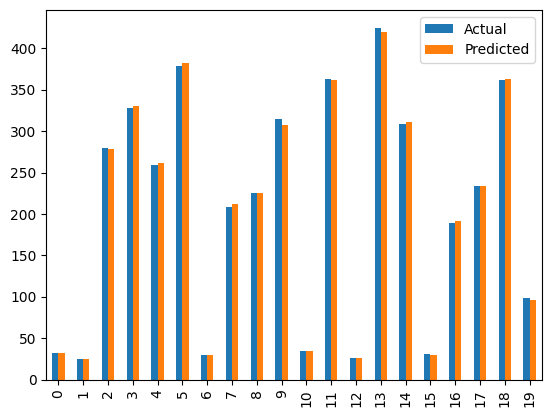

In [ ]:
new.plot(kind="bar")

In [ ]:
metrics.mean_absolute_error(y_test,prediction)

1.3295570713362095

In [ ]:
metrics.mean_squared_error(y_test,prediction)

4.168987511037963

In [ ]:
print("Accuracy of the model is:",np.round(metrics.r2_score(y_test,prediction)*100,2))

Accuracy of the model is: 99.97


In [ ]:
import pickle
pickle.dump(model, open('model.pkl', 'wb'))
print("pkl file genetrated")

pkl file genetrated
